# Kinase Module Heatmap

Defines kinase modules by clustering on shared leading-edge substrate patterns, then draws the module- and family-colored clustermap.

Depends on `kl_en_res_lightweight.pkl`, `bmdm_expressed_proteins_gene_symbols.txt`

## 0. Imports & paths

In [2]:
import os
import pickle
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import pdist
from matplotlib.patches import Patch

enr_f    = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/KL_motif_enrichment_res/out_files/kl_en_res_lightweight.pkl"
expressed_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/macs_proteomics/bmdm_expressed_proteins_gene_symbols.txt"
out_path = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap"
os.makedirs(f"{out_path}/figures", exist_ok=True)
os.makedirs(f"{out_path}/out_files", exist_ok=True)

# Dropped the 3 IL6-vs-IL10 head-to-head contrasts -- keeping only the 6
# cytokine-vs-baseline (over_0min) contrasts.
sign_logp_cols = [
    "sign.logP.IL6_20min_over_0min",
    "sign.logP.IL6_45min_over_0min",
    "sign.logP.IL6_90min_over_0min",
    "sign.logP.IL10_20min_over_0min",
    "sign.logP.IL10_45min_over_0min",
    "sign.logP.IL10_90min_over_0min",
]
contrast_labels = [c.split(".")[-1] for c in sign_logp_cols]

## 1. Load lightweight enrichment results

In [3]:
with open(enr_f, "rb") as f:
    lightweight = pickle.load(f)

enrichment_tables = lightweight["enrichment_tables"]
kinase_family_map = lightweight["kinase_family_map"]
ser_thr_tables = enrichment_tables['ser_thr']

print(f"Contrasts available: {list(ser_thr_tables.keys())}")

Contrasts available: ['sign.logP.IL6_20min_over_IL10_20min', 'sign.logP.IL6_45min_over_IL10_45min', 'sign.logP.IL6_90min_over_IL10_90min', 'sign.logP.IL6_20min_over_0min', 'sign.logP.IL6_45min_over_0min', 'sign.logP.IL6_90min_over_0min', 'sign.logP.IL10_20min_over_0min', 'sign.logP.IL10_45min_over_0min', 'sign.logP.IL10_90min_over_0min']


## 2. Rebuild the significant-kinase set and binary leading-edge matrix

Same logic as `compile_kinase_meas_lightweight.py` -- modules are defined on this matrix.

In [4]:
sig_kinases = set()
for contrast, tbl in ser_thr_tables.items():
    sig = tbl[tbl['FDR'] < 0.05]
    sig_kinases.update(sig.index.tolist())
all_kinases = list(sig_kinases)
print(f"Significant kinases (any contrast, FDR<0.05): {len(all_kinases)}")

Significant kinases (any contrast, FDR<0.05): 274


### Subset to expressed proteins

Filter `all_kinases` down to kinases actually expressed in BMDMs.

In [5]:
with open(expressed_f) as f:
    expressed_genes = set(line.strip().upper() for line in f if line.strip())

print(f"Expressed genes loaded: {len(expressed_genes)}")

n_before = len(all_kinases)
all_kinases = [k for k in all_kinases if k.upper() in expressed_genes]
print(f"Significant kinases: {n_before} -> {len(all_kinases)} after subsetting to expressed proteins")

Expressed genes loaded: 6950
Significant kinases: 274 -> 83 after subsetting to expressed proteins


In [6]:
all_dicts = []
for CONDITION_COL in sign_logp_cols:
    plot_interacts = ser_thr_tables[CONDITION_COL].loc[all_kinases, :]
    encoding_dict = {}
    for kinase, row in plot_interacts.iterrows():
        sub_list = [f"{x}__{CONDITION_COL.split('.')[-1]}"
                    for x in row["Leading substrates"].split(";")]
        encoding_dict[kinase] = sub_list
    all_dicts.append(encoding_dict)

compile_dict = {
    key: list(chain.from_iterable([d.get(key, []) for d in all_dicts]))
    for key in sorted(set().union(*all_dicts))
}
kinase_order = list(compile_dict.keys())  # row order, fixed from here on

mlb = MultiLabelBinarizer()
mtx = mlb.fit_transform(compile_dict.values())
print(f"Binary matrix: {mtx.shape[0]} kinases x {mtx.shape[1]} substrate-condition tags")

Binary matrix: 83 kinases x 34245 substrate-condition tags


## 3. Cluster kinases and cut into discrete modules

In [7]:
n_modules = 12  # <-- ADJUST and re-run this cell + below to compare cuts

row_linkage = linkage(pdist(mtx, metric="correlation"), method="complete")
module_labels = fcluster(row_linkage, t=n_modules, criterion="maxclust")

module_df = pd.DataFrame({
    "kinase": kinase_order,
    "module": module_labels,
    "family": [kinase_family_map.get(k, "unknown") for k in kinase_order],
})

print("Module sizes:")
print(module_df["module"].value_counts().sort_index())

Module sizes:
module
1     17
2     10
3      6
4      4
5      4
6      4
7      5
8      4
9      5
10     4
11     7
12    13
Name: count, dtype: int64


## 3b. Clustermap of the binary substrate matrix, colored by module + family

Columns are deduplicated before clustering (many columns are exact duplicates -- a kinase with 150 leading substrates in one contrast produces 150 identical columns), clustered on the unique patterns only, then expanded back out.

In [8]:
# --- Deduplicate columns before clustering (avoids OOM on full pdist) ---
print("Deduplicating columns before clustering...")
unique_cols, inverse = np.unique(mtx, axis=1, return_inverse=True)
n_unique = unique_cols.shape[1]
print(f"  {mtx.shape[1]} columns -> {n_unique} unique patterns "
      f"({100 * n_unique / mtx.shape[1]:.2f}% retained)")

print("Computing column linkage on unique patterns only...")
unique_col_linkage = linkage(pdist(unique_cols.T, metric="euclidean"), method="ward")

# Expand the unique-pattern leaf order back out to a full column order
unique_leaf_order = leaves_list(unique_col_linkage)
full_col_order = []
for u in unique_leaf_order:
    full_col_order.extend(np.where(inverse == u)[0].tolist())
full_col_order = np.array(full_col_order)

mtx_reordered = mtx[:, full_col_order]
classes_reordered = mlb.classes_[full_col_order]

Deduplicating columns before clustering...
  34245 columns -> 9438 unique patterns (27.56% retained)
Computing column linkage on unique patterns only...


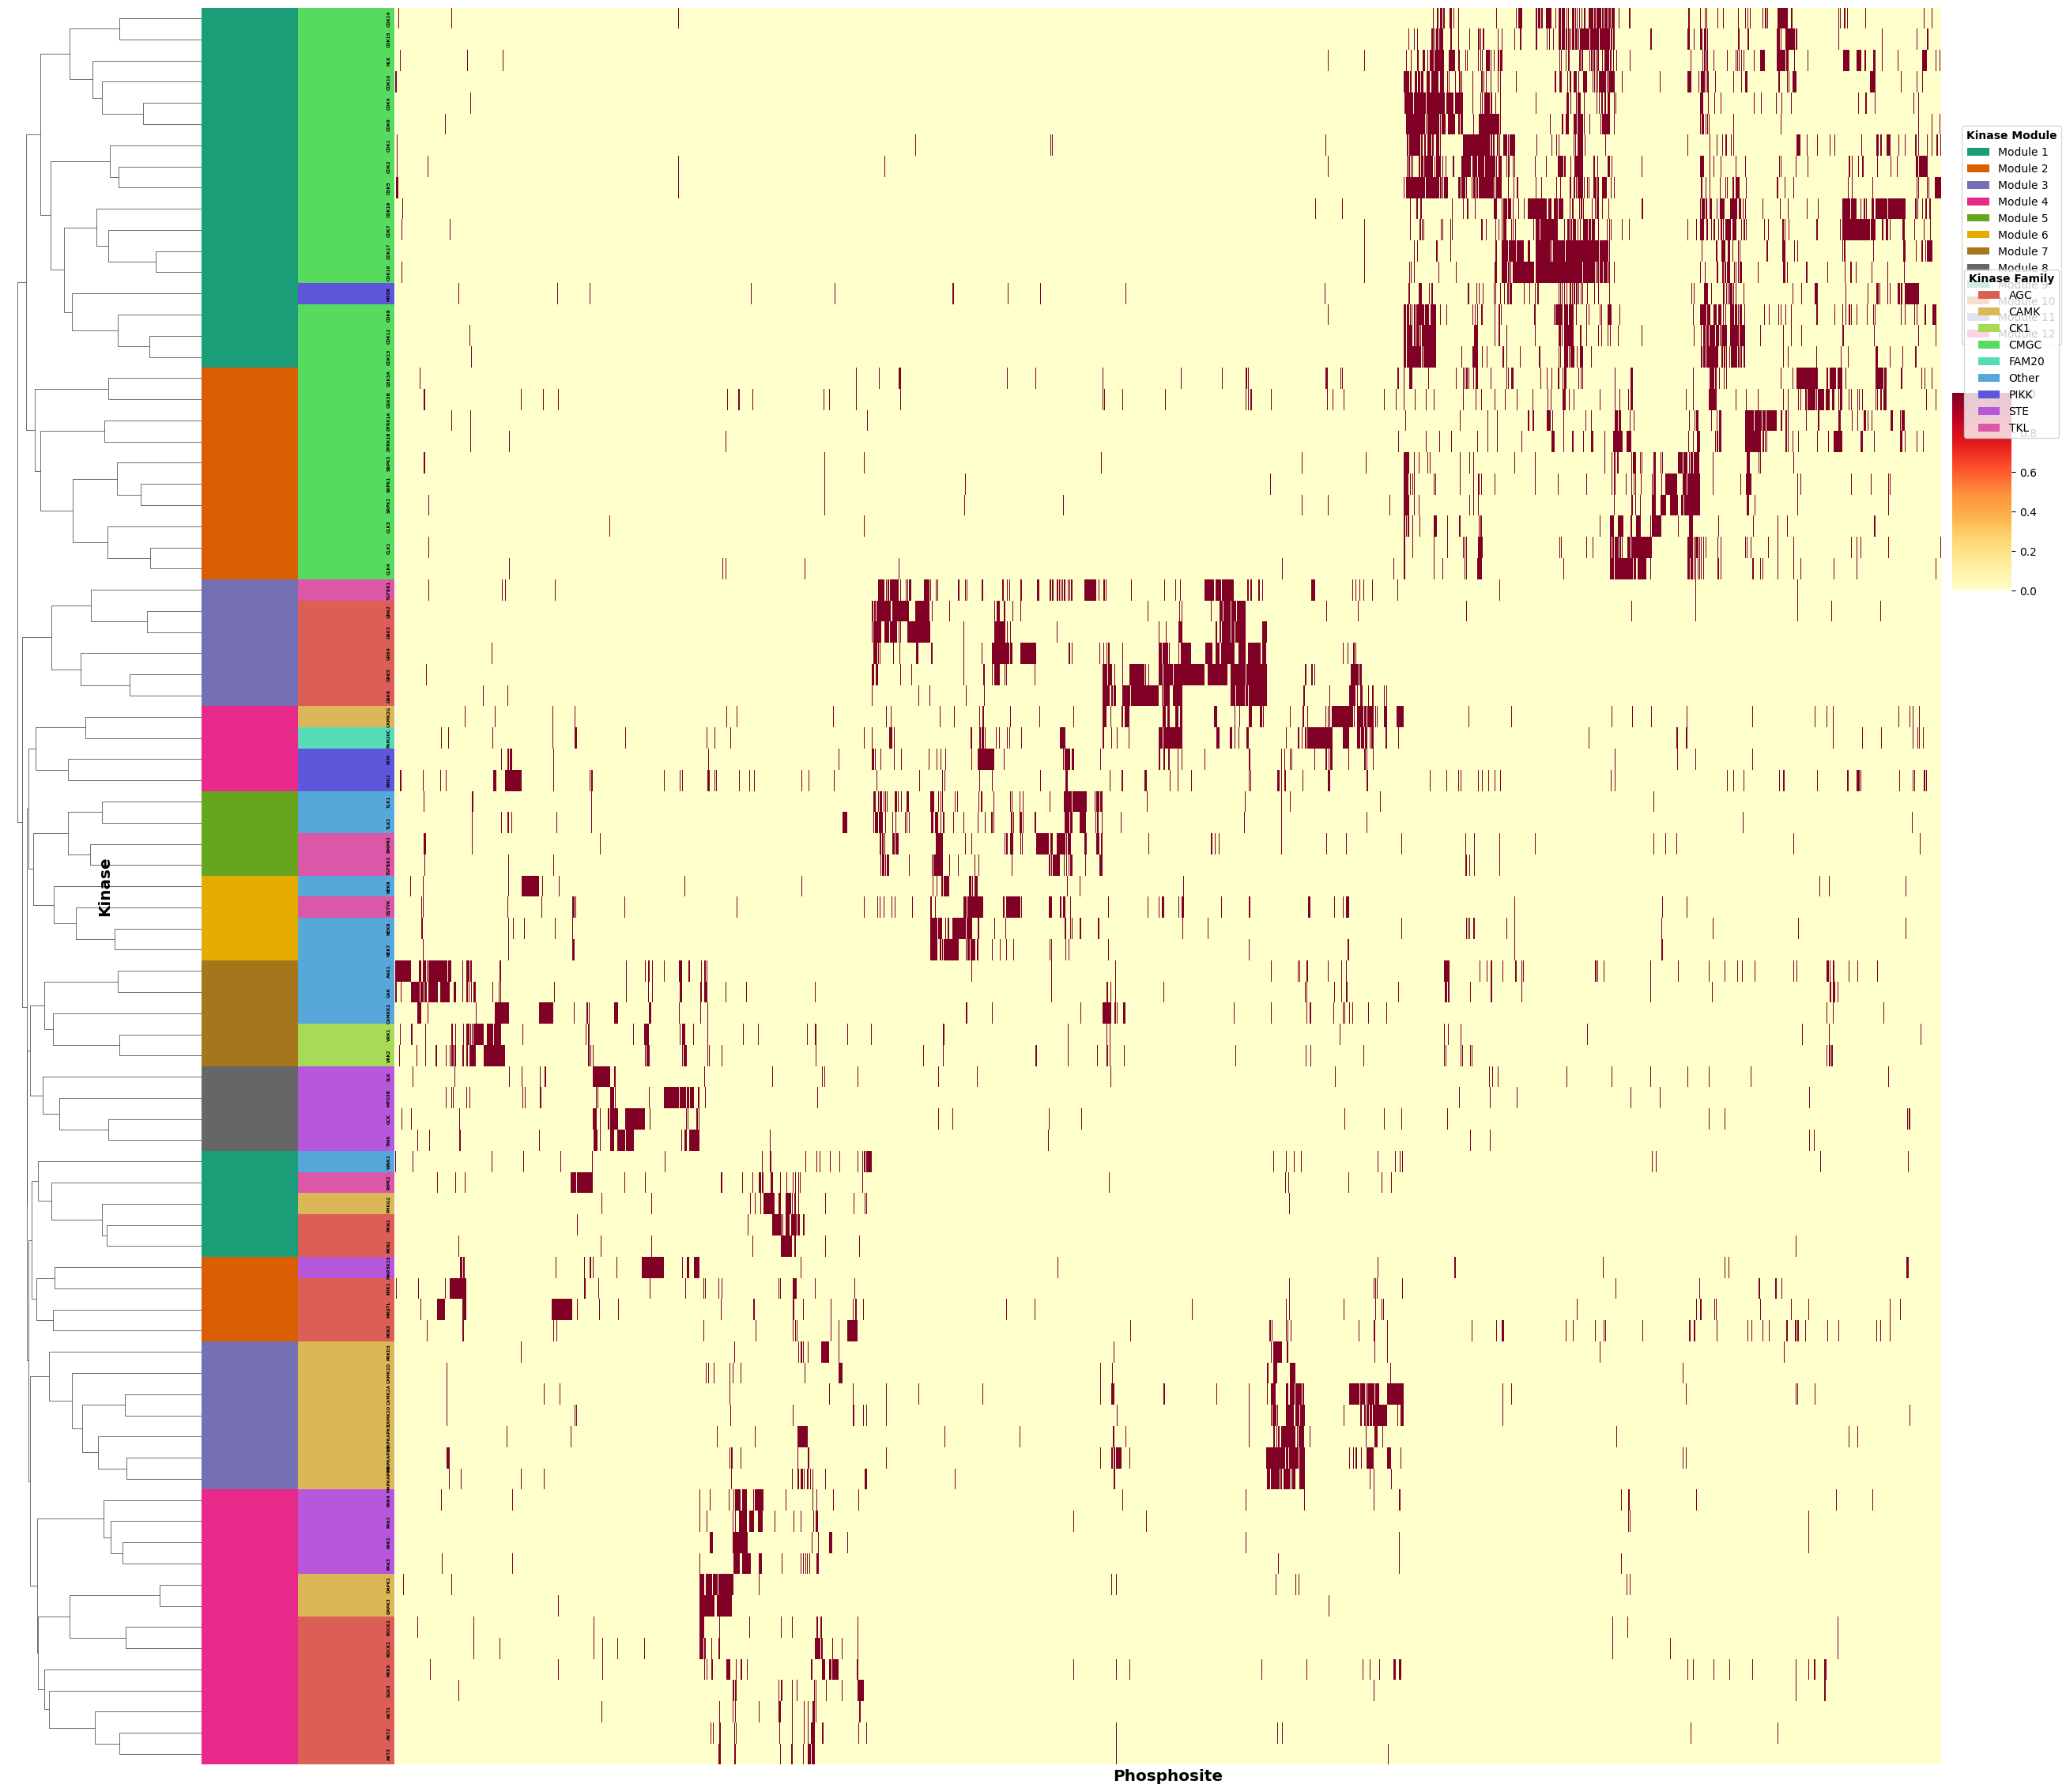

In [9]:
# Try different qualitative, publication-friendly palettes by changing
# MODULE_CMAP and re-running this cell + the save cell below. Good options
# for ~12 categories:
#   "Set3"   -- ColorBrewer qualitative, pastel, sized for up to 12 categories
#   "Paired" -- ColorBrewer qualitative, sized for up to 12 categories
#   "tab20"  -- matplotlib's 20-color qualitative set
#   "husl"   -- seaborn's evenly-spaced-hue palette, any n, more saturated
#   "Dark2"  -- ColorBrewer qualitative, max 8 distinct (cycles if n_modules>8)
MODULE_CMAP = "Dark2"

module_palette = sns.color_palette(MODULE_CMAP, n_modules)
module_lut = dict(zip(sorted(module_df["module"].unique()), module_palette))

all_kin_types = np.unique([kinase_family_map[x] for x in kinase_order])
family_palette = sns.color_palette("hls", len(all_kin_types))
family_lut = dict(zip(all_kin_types, family_palette))

kinase_labels = kinase_order  # must match mtx row order exactly

# Two annotation tracks -- seaborn's multi-track row_colors expects a list of
# per-track color lists (outer length = number of tracks)
module_colors = [module_lut[m] for m in module_df["module"]]
family_colors = [family_lut[kinase_family_map[k]] for k in kinase_order]
row_colors = [module_colors, family_colors]

g = sns.clustermap(
    data=mtx_reordered, cmap="YlOrRd", yticklabels=True, figsize=(25, 25),
    dendrogram_ratio=0.1, cbar_pos=(0.99, 0.6, 0.03, 0.1),
    row_colors=row_colors, xticklabels=False, colors_ratio=0.05,
    row_linkage=row_linkage, col_cluster=False,
)

g.ax_heatmap.set_xlabel("Phosphosite", fontsize="x-large", fontweight="bold")
g.ax_heatmap.set_ylabel("Kinase", fontsize="x-large", fontweight="bold", labelpad=250)
g.ax_heatmap.yaxis.set_label_position("left")
g.ax_heatmap.set_xticklabels([])

row_leaf_order = leaves_list(row_linkage)
y_labels = [kinase_labels[i] for i in row_leaf_order]
g.ax_heatmap.set_yticklabels(y_labels, fontsize=4, fontweight="bold")
g.ax_heatmap.tick_params(axis='y', length=0)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(left=True, right=False, labelleft=True, labelright=False)

module_legend_elements = [Patch(facecolor=module_lut[m], label=f"Module {m}") for m in sorted(module_lut)]
module_legend = plt.gca().legend(
    handles=module_legend_elements, loc='center', title="Kinase Module",
    bbox_to_anchor=(1., 1.8), title_fontproperties={'weight': 'bold'}
)
plt.gca().add_artist(module_legend)

family_legend_elements = [Patch(facecolor=family_lut[f], label=f) for f in family_lut.keys()]
plt.gca().legend(
    handles=family_legend_elements, loc='center', title="Kinase Family",
    bbox_to_anchor=(1., 1.2), title_fontproperties={'weight': 'bold'}
)

## Save PNG and SVG

For SVG: rasterizing the heatmap body (and the row-color side strips) before saving, since a true-vector heatmap would draw one vector path per cell

In [10]:
for collection in g.ax_heatmap.collections:
    collection.set_rasterized(True)
for collection in g.ax_row_colors.collections:
    collection.set_rasterized(True)

png_out = f"{out_path}/figures/fig3a_FULL_kinase_module_heatmap.png"
svg_out = f"{out_path}/figures/fig3a_FULL_kinase_module_heatmap.svg"

g.savefig(png_out, dpi=300, bbox_inches="tight")
g.savefig(svg_out, dpi=300, bbox_inches="tight")

print(f"Saved: {png_out}")
print(f"Saved: {svg_out}  (heatmap body rasterized, text/dendrogram/legend remain vector)")

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/figures/fig3a_FULL_kinase_module_heatmap.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/figures/fig3a_FULL_kinase_module_heatmap.svg  (heatmap body rasterized, text/dendrogram/legend remain vector)


## 4. Save module assignments and underlying dataframe

In [11]:
print("Module x family composition:")
display(pd.crosstab(module_df["module"], module_df["family"]))

module_df.to_csv(f"{out_path}/out_files/kinase_module_assignments.csv", index=False)
print("Saved: kinase_module_assignments.csv")

Module x family composition:


family,AGC,CAMK,CK1,CMGC,FAM20,Other,PIKK,STE,TKL
module,,,,,,,,,
1,0,0,0,16,0,0,1,0,0
2,0,0,0,10,0,0,0,0,0
3,5,0,0,0,0,0,0,0,1
4,0,1,0,0,1,0,2,0,0
5,0,0,0,0,0,2,0,0,2
6,0,0,0,0,0,3,0,0,1
7,0,0,2,0,0,3,0,0,0
8,0,0,0,0,0,0,0,4,0
9,2,1,0,0,0,1,0,0,1


Saved: kinase_module_assignments.csv


In [12]:
mtx_fully_reordered = mtx_reordered[row_leaf_order, :]
save_df = pd.DataFrame(mtx_fully_reordered)
save_df.index = y_labels
save_df.columns = classes_reordered
save_df.to_csv(f"{out_path}/out_files/module_clustermap_dataframe.csv")
print("Saved: module_clustermap_dataframe.csv")

Saved: module_clustermap_dataframe.csv


## 5. Final heatmap -- modules 4, 9, 10, 12 excluded for sparsity

Kinases: 83 -> 57 after excluding modules [4, 9, 10, 12]
Columns: 34245 -> 30417 after dropping now-empty columns


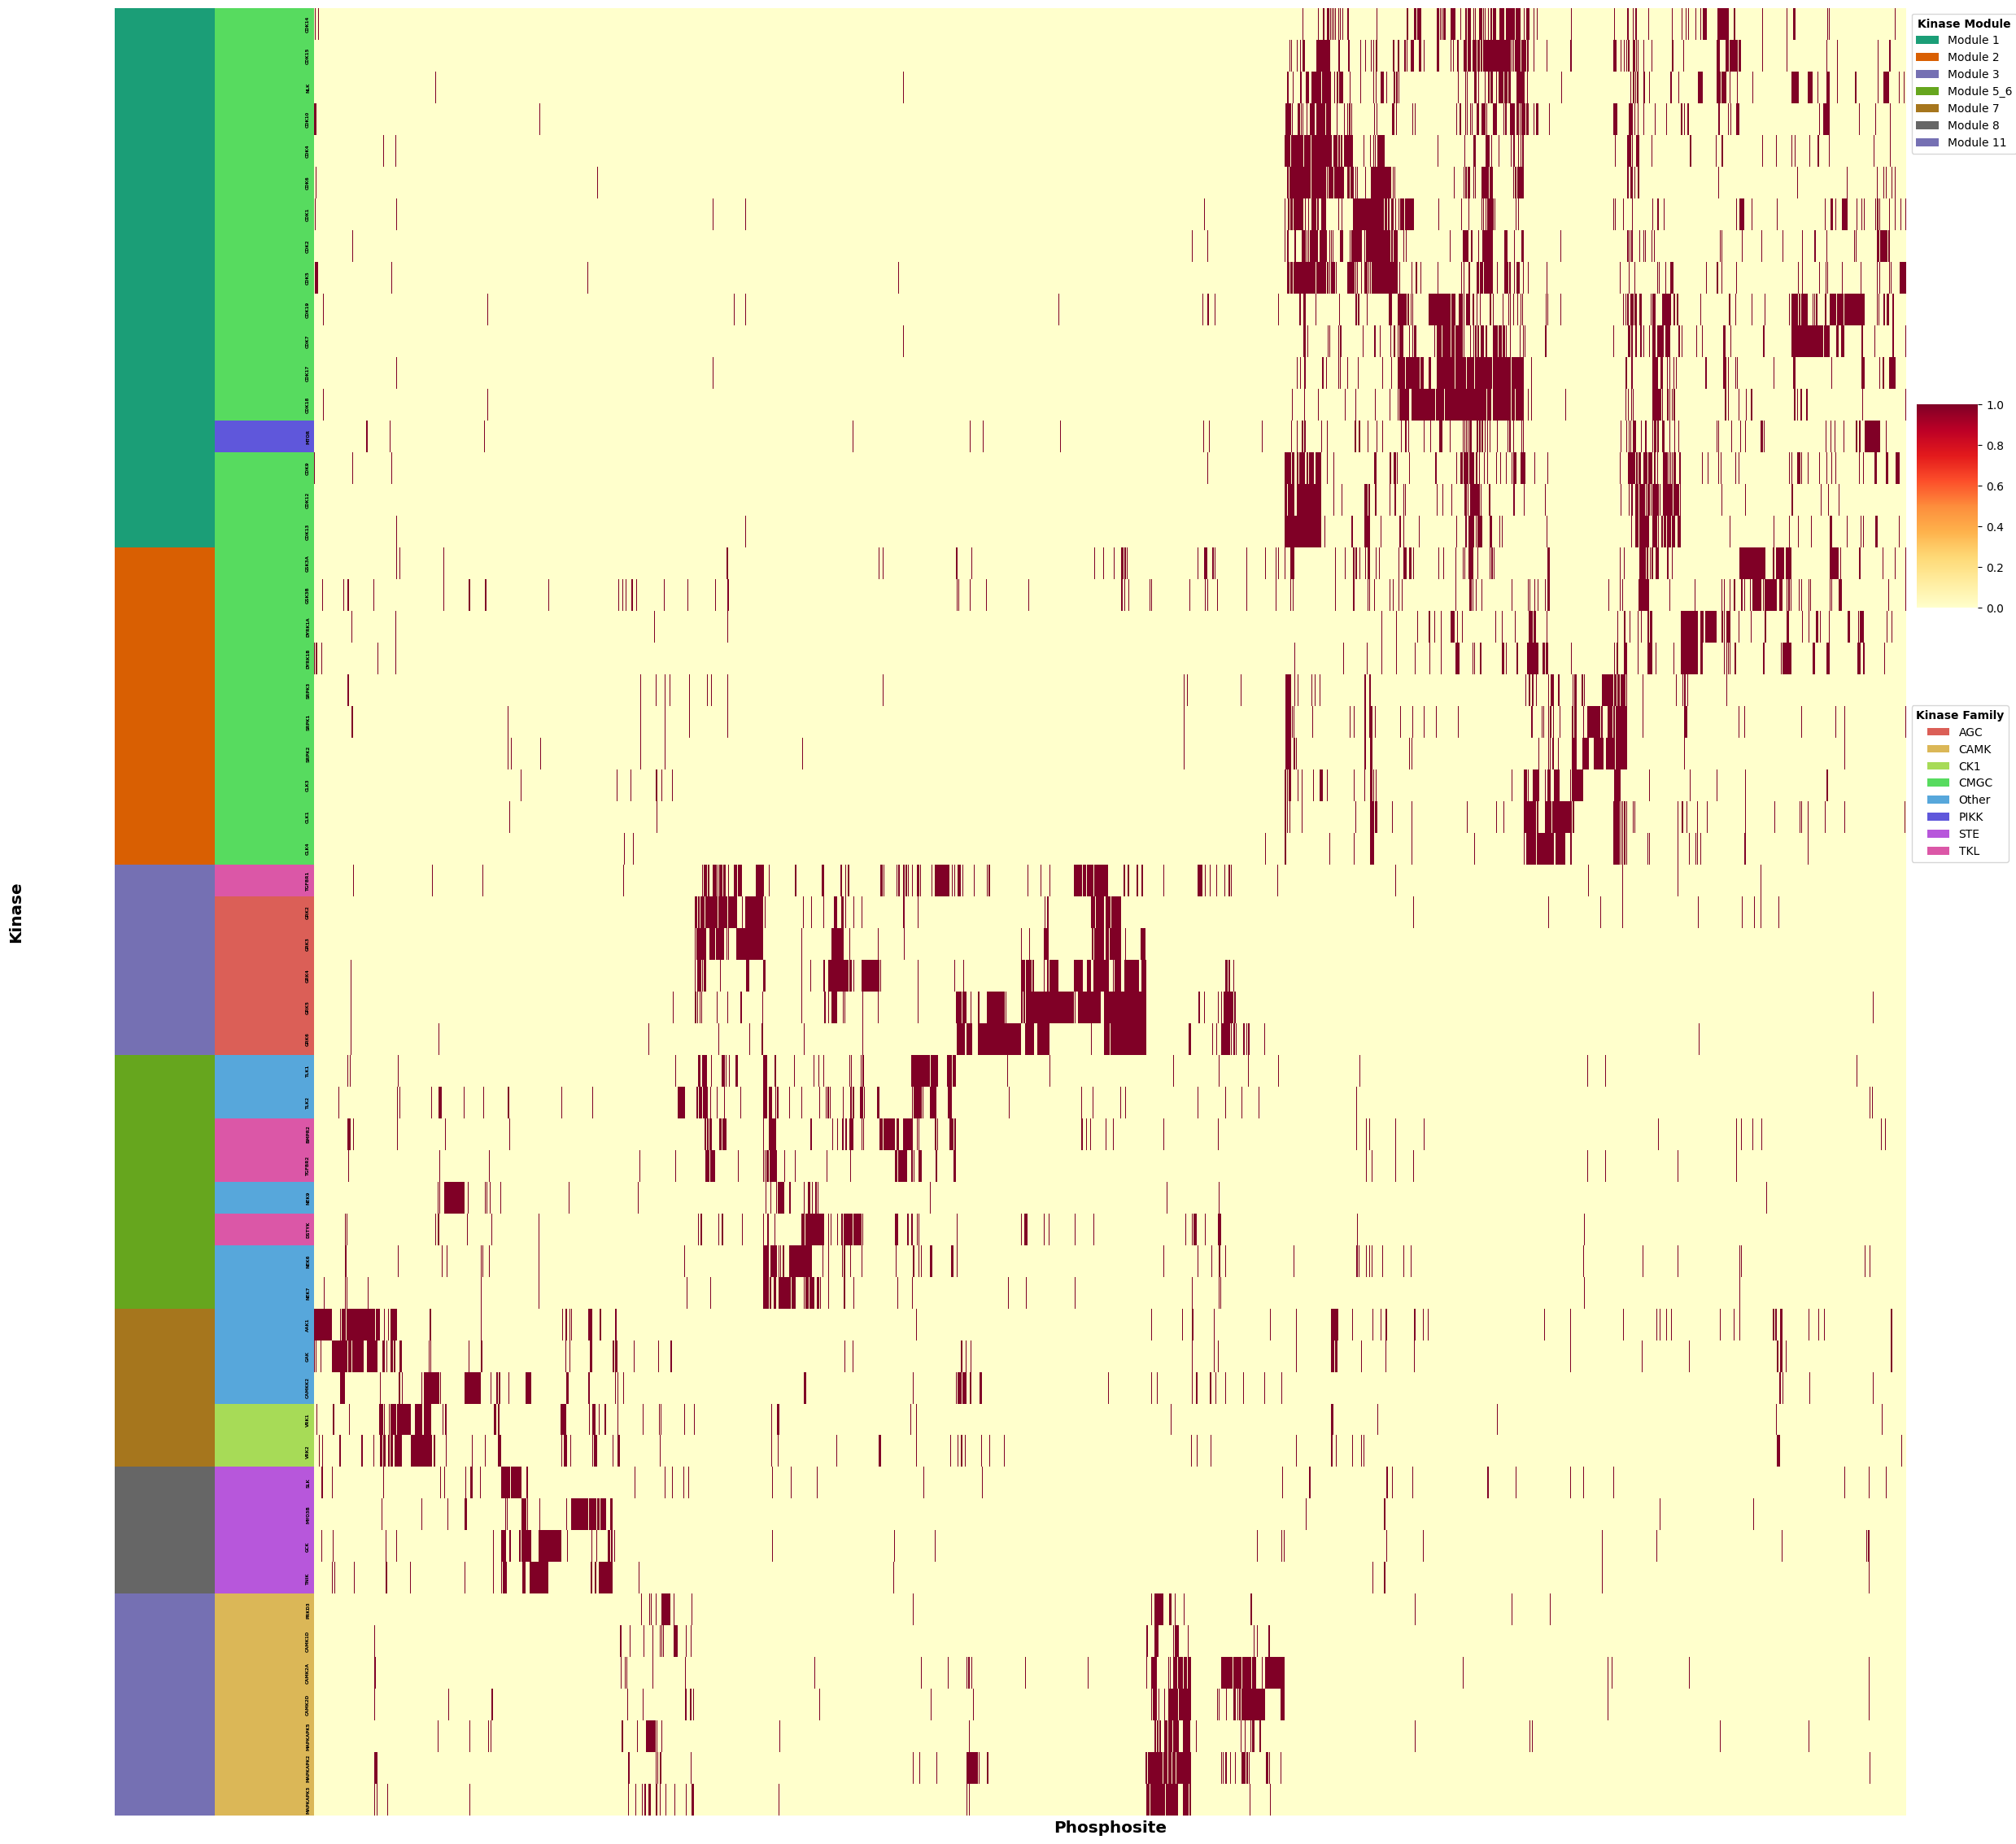

In [13]:
EXCLUDED_MODULES = [4, 9, 10, 12]

# Merge modules 5 and 6 into one meta-module ("5_6") for THIS heatmap's
# display only -- kinase_to_module / module_df stay completely
# untouched everywhere else in the notebook, this is purely a
# relabeling of how modules 5 and 6 are colored and legended here. Row
# order is NOT changed -- kinases keep whatever position the natural
# full clustering (section 3) already put them in.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

kinase_to_module = dict(zip(module_df["kinase"], module_df["module"]))

keep_positions = [i for i, lbl in enumerate(y_labels) if kinase_to_module[lbl] not in EXCLUDED_MODULES]
y_labels_final = [y_labels[i] for i in keep_positions]
mtx_final = mtx_fully_reordered[keep_positions, :]

# drop columns that are now all-zero (only had leading substrates from excluded kinases)
nonzero_cols = mtx_final.sum(axis=0) > 0
mtx_final = mtx_final[:, nonzero_cols]
classes_final = classes_reordered[nonzero_cols]

print(f"Kinases: {len(y_labels)} -> {len(y_labels_final)} after excluding modules {EXCLUDED_MODULES}")
print(f"Columns: {mtx_fully_reordered.shape[1]} -> {mtx_final.shape[1]} after dropping now-empty columns")

# colors/legend only for modules & families actually present in the final subset
modules_present_raw = sorted(set(kinase_to_module[lbl] for lbl in y_labels_final))
modules_present = sorted(
    set(display_module(m) for m in modules_present_raw),
    key=lambda d: min(m for m in modules_present_raw if display_module(m) == d),
)
families_present = sorted(set(kinase_family_map[lbl] for lbl in y_labels_final))

# module_lut needs a color for the merged "5_6" label too -- reuse module 5's original color
module_lut_display = dict(module_lut)
if "5_6" in modules_present:
    module_lut_display["5_6"] = module_lut[5]

module_colors_final = [module_lut_display[display_module(kinase_to_module[lbl])] for lbl in y_labels_final]
family_colors_final = [family_lut[kinase_family_map[lbl]] for lbl in y_labels_final]
row_colors_final = [module_colors_final, family_colors_final]

g_final = sns.clustermap(
    data=mtx_final, cmap="YlOrRd", yticklabels=True, figsize=(25, 25),
    dendrogram_ratio=0.1, cbar_pos=(0.99, 0.6, 0.03, 0.1),
    row_colors=row_colors_final, xticklabels=False, colors_ratio=0.05,
    row_cluster=False, col_cluster=False,
)

g_final.ax_heatmap.set_xlabel("Phosphosite", fontsize="x-large", fontweight="bold")
g_final.ax_heatmap.set_ylabel("Kinase", fontsize="x-large", fontweight="bold", labelpad=250)
g_final.ax_heatmap.yaxis.set_label_position("left")
g_final.ax_heatmap.set_xticklabels([])
g_final.ax_heatmap.set_yticklabels(y_labels_final, fontsize=4, fontweight="bold")
g_final.ax_heatmap.tick_params(axis='y', length=0)
g_final.ax_col_dendrogram.set_visible(False)
g_final.ax_row_dendrogram.set_visible(False)
g_final.ax_heatmap.tick_params(left=True, right=False, labelleft=True, labelright=False)

n_module_entries = len(modules_present)

module_legend_elements_final = [Patch(facecolor=module_lut_display[m], label=f"Module {m}") for m in modules_present]
module_legend_final = g_final.ax_heatmap.legend(
    handles=module_legend_elements_final, loc='upper left', title="Kinase Module",
    bbox_to_anchor=(1.0, 1.0), title_fontproperties={'weight': 'bold'}
)
g_final.ax_heatmap.add_artist(module_legend_final)

family_legend_elements_final = [Patch(facecolor=family_lut[f], label=f) for f in families_present]
family_legend_final = g_final.ax_heatmap.legend(
    handles=family_legend_elements_final, loc='upper left', title="Kinase Family",
    bbox_to_anchor=(1.0, 1.0 - 0.045 * (n_module_entries + 1.5)),  # +1.5 accounts for the title row
    title_fontproperties={'weight': 'bold'}
)

## 6. Save final heatmap PNG and SVG

In [14]:
for collection in g_final.ax_heatmap.collections:
    collection.set_rasterized(True)
for collection in g_final.ax_row_colors.collections:
    collection.set_rasterized(True)

png_out_final = f"{out_path}/figures/fig3a_final_kinase_module_heatmap.png"
svg_out_final = f"{out_path}/figures/fig3a_final_kinase_module_heatmap.svg"

g_final.savefig(png_out_final, dpi=300, bbox_inches="tight")
g_final.savefig(svg_out_final, dpi=300, bbox_inches="tight")

print(f"Saved: {png_out_final}")
print(f"Saved: {svg_out_final}")

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/figures/fig3a_final_kinase_module_heatmap.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/figures/fig3a_final_kinase_module_heatmap.svg
